In [6]:
import pandas as pd
print("pandas version:", pd.__version__)
import numpy as np
print("numpy version:", np.__version__)

import seaborn as sns
print("Seaborn version:", sns.__version__)
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
print("matplotlib version:", matplotlib.__version__)
import scipy
from scipy.stats import ttest_ind
from scipy.cluster.hierarchy import linkage
print("scipy version:", scipy.__version__)
import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
print("Seaborn version:", sklearn.__version__)

from statannot import add_stat_annotation
from statannotations.Annotator import Annotator
import statannotations
print("Statannotations version:", statannotations.__version__)
import warnings
warnings.filterwarnings('ignore')


pandas version: 1.5.3
numpy version: 1.25.2
Seaborn version: 0.11.2
matplotlib version: 3.7.2
scipy version: 1.11.1
Seaborn version: 1.5.1
Statannotations version: 0.5.0


Give some basic Statistics

64.0
35.64
2.01
6.54


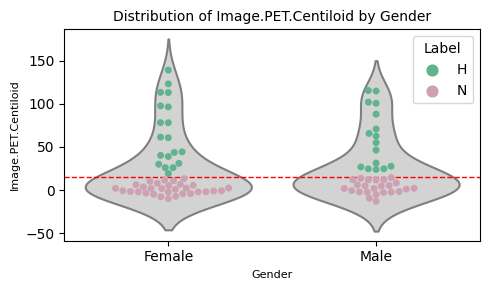

In [99]:
check_centiloid = pd.read_excel('../data/raw_data/check.xlsx', sheet_name='Centiloid')
check_centiloid['Gender'] = check_centiloid['Gender'].replace({'M':"Male", 'F': "Female"})
######## Female ########
check_df_F=check_centiloid[check_centiloid['label']=='H']
######## Male ########
check_df_M=check_centiloid[check_centiloid['label']=='N']
plt.figure(figsize=(5, 3))

sns.violinplot(
    x='Gender',
    y='Image.PET.Centiloid',
    data=check_centiloid,
    scale='width',
    linewidth=1.5,
    inner=None,  # Remove the default inner bars
    color='lightgray'
)

# Define custom colors for the dots
custom_palette = {'H': '#5fb38d', 'N': '#cda1b1'}  # Replace with your desired colors

# Overlay a swarm plot with dots colored based on the 'label' column
sns.swarmplot(
    x='Gender',
    y='Image.PET.Centiloid',
    data=check_centiloid,
    hue='label',
    dodge=False,  # Do not separate the dots horizontally
    size=5,
    palette=custom_palette  # Use the custom color palette
)

plt.axhline(y=15, color='red', linestyle='--', linewidth=1)
plt.title('Distribution of Image.PET.Centiloid by Gender', fontsize=10)
plt.xlabel('Gender', fontsize=8)
plt.ylabel('Image.PET.Centiloid', fontsize=8)

plt.legend(
    title='Label',
    loc='upper right', 
    bbox_to_anchor=(1, 1)
)

# Show the plot
plt.tight_layout()
plt.show()


In [61]:
omics_with_demo_df = pd.read_csv('../data/merged_data/omics_aibl_demo_impute.csv', index_col=False)
omics_with_demo_df = omics_with_demo_df.drop(['Gender'], axis=1)
basic_statistics_ft = ['Demographic.Years.of.Education.Exact', 'Age', 'Demographic.Sex', 'Demographic.ApoE.genotype', 'label','AIBL.ID','Collection']
basic_statis_info_df_APOE = omics_with_demo_df[basic_statistics_ft]

In [62]:
basic_statis_info_df_APOE['Demographic.ApoE.genotype'].unique()

array(['E4/E2', 'E3/E3', 'E4/E3', 'E3/E2', 'E4/E4'], dtype=object)

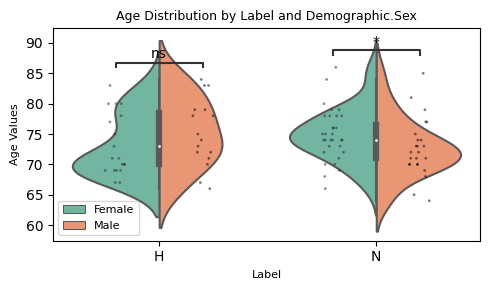

In [63]:
feature_name = 'Age'
hue_name = 'Demographic.Sex'

plt.figure(figsize=(5, 3))
ax = sns.violinplot(x='label', y=feature_name, data=basic_statis_info_df_APOE, hue=hue_name, split=True, palette="Set2")

# Stripplot without adding to the legend
strip = sns.stripplot(x='label', y=feature_name, data=basic_statis_info_df_APOE, hue=hue_name, color='k', size=2, alpha=0.5, dodge=True)
strip.legend_.remove()  # Remove legend for stripplot

labels = basic_statis_info_df_APOE['label'].unique()
hues = basic_statis_info_df_APOE[hue_name].unique()
pairs = [((label, hues[0]), (label, hues[1])) for label in labels]

annotator = Annotator(ax, pairs, data=basic_statis_info_df_APOE, x='label', y=feature_name, hue=hue_name)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0, line_offset=0.05)
annotator.apply_and_annotate()

ax.set_title(f'{feature_name} Distribution by Label and {hue_name}', fontsize=9)
ax.set_xlabel('Label', fontsize=8)
ax.set_ylabel(f'{feature_name} Values', fontsize=8)

# Adjust legend for violinplot only
handles, labels = ax.get_legend_handles_labels()
n = len(basic_statis_info_df_APOE[hue_name].unique())  # number of hue categories
plt.legend(handles[:n], labels[:n], loc='best', fontsize=8)  # Show legend only for violinplot hues

plt.tight_layout()
plt.show()

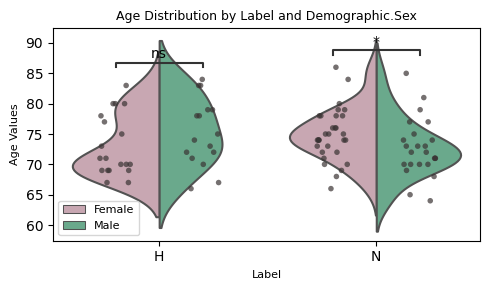

In [64]:
feature_name = 'Age'
hue_name = 'Demographic.Sex'

plt.figure(figsize=(5, 3))

violin_palette = {"Male": "#5fb38d", "Female": "#cda1b1"}  # Define custom colors for the outline

# Violinplot with transparent interior (no color) and colored outline
ax = sns.violinplot(x='label', y=feature_name, data=basic_statis_info_df_APOE, hue=hue_name, split=True, 
                    palette=violin_palette, inner=None, linewidth=1.5, facecolor=(0, 0, 0, 0))  # Transparent fill, colored outline


# Custom colors for stripplot dots
strip_palette = {"Male": "#3a3434", "Female": "#3a3434"}  # Define custom colors for dots

# Stripplot with custom colors for dots
strip = sns.stripplot(x='label', y=feature_name, data=basic_statis_info_df_APOE, hue=hue_name, 
                      palette=strip_palette, size=4, alpha=0.7, dodge=True, jitter=0.15)  # Larger dots, less jitter
strip.legend_.remove()  # Remove legend for stripplot

# Get unique labels and hues
labels = basic_statis_info_df_APOE['label'].unique()
hues = basic_statis_info_df_APOE[hue_name].unique()

# Define pairs for annotation
pairs = [((label, hues[0]), (label, hues[1])) for label in labels]

# Annotator configuration
annotator = Annotator(ax, pairs, data=basic_statis_info_df_APOE, x='label', y=feature_name, hue=hue_name)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0, line_offset=0.05)
annotator.apply_and_annotate()

# Customize title and axis labels
ax.set_title(f'{feature_name} Distribution by Label and {hue_name}', fontsize=9)
ax.set_xlabel('Label', fontsize=8)
ax.set_ylabel(f'{feature_name} Values', fontsize=8)

# Adjust legend to show for the violin plot hues only
handles, labels = ax.get_legend_handles_labels()
n = len(basic_statis_info_df_APOE[hue_name].unique())  # Number of hue categories
plt.legend(handles[:n], labels[:n], loc='best', fontsize=8)  # Show legend only for violinplot hues

plt.tight_layout()
plt.show()


In [65]:
basic_statistics_ft = ['Demographic.Years.of.Education.Exact', 'Age', 'Demographic.Sex', 'Demographic.ApoE.genotype', 'label','AIBL.ID','Collection']
basic_statis_info_df = omics_with_demo_df[basic_statistics_ft]
# basic_statis_info_df['Demographic.ApoE genotype'] = basic_statis_info_df['Demographic.ApoE genotype'].str.contains('E4', na=False).astype(int)
basic_statis_info_df['APOE4'] = np.where(
basic_statis_info_df['Demographic.ApoE.genotype'].str.contains('E4', na=False),
    1,
    np.where(basic_statis_info_df['Demographic.ApoE.genotype'].isna(),np.nan,0)
)

In [66]:
plus_minus = '\u00B1'
def calculate_stats(df, df_name):
    female_count = df[df['Demographic.Sex'] == "Female"].shape[0]
    female_proportion = round((female_count/df.shape[0])* 100,2)
    apoe_counts = df[df['APOE4']== 1].shape[0]
    apoe_proportions = round((apoe_counts / df.shape[0])*100, 2)
    
    age_mean = round(df['Age'].mean(), 2)
    age_std = round(df['Age'].std(), 2)


    Edu_mean = round(df['Demographic.Years.of.Education.Exact'].mean(), 2)
    Edu_std = round(df['Demographic.Years.of.Education.Exact'].std(), 2)

    
   
    return {"Group Name":f"{df_name} (n={df.shape[0]})",
           "Sex": f'{female_count} ({female_proportion}%)',
           "Age": f"{age_mean} {plus_minus} {age_std}",
           "APOE4": f'{apoe_counts} ({apoe_proportions}%)',
           "Education (year)": f"{Edu_mean} {plus_minus} {Edu_std}"
        #    "CDR final": f"{cdr_end_mean} {plus_minus} {cdr_end_std}",
           }


datasets = [(basic_statis_info_df, "Full dataset"), 
            (basic_statis_info_df[basic_statis_info_df['label']=="H"], "Amyloid-beta High"),
            (basic_statis_info_df[basic_statis_info_df['label']=="N"], "Amyloid-beta Normal")]
summary_stats = pd.DataFrame()
for (cur_df, cur_df_name) in datasets:
    summary_stats = pd.concat([summary_stats, pd.DataFrame([calculate_stats(cur_df, cur_df_name)])], ignore_index=True)
summary_stats

,Group Name,Sex,Age,APOE4,Education (year)
0,Full dataset (n=90),50 (55.56%),73.97 ± 4.87,31 (34.44%),13.34 ± 2.85
1,Amyloid-beta High (n=35),19 (54.29%),74.06 ± 5.35,16 (45.71%),13.03 ± 2.7
2,Amyloid-beta Normal (n=55),31 (56.36%),73.91 ± 4.6,15 (27.27%),13.55 ± 2.95


In [67]:
pd.crosstab(basic_statis_info_df['label'], basic_statis_info_df['APOE4'])

APOE4,0.0,1.0
label,,
H,19,16
N,40,15


In [68]:
plus_minus = '\u00B1'
def calculate_stats_sex(df, df_name):
    amyloid_high_count = df[df['label'] == 'H'].shape[0]
    amyloid_high_proportion = round((amyloid_high_count/df.shape[0])* 100,2)
    apoe_counts = df[df['APOE4']== 1].shape[0]
    apoe_proportions = round((apoe_counts / df.shape[0])*100, 2)
    
    age_mean = round(df['Age'].mean(), 2)
    age_std = round(df['Age'].std(), 2)


    Edu_mean = round(df['Demographic.Years.of.Education.Exact'].mean(), 2)
    Edu_std = round(df['Demographic.Years.of.Education.Exact'].std(), 2)

    
   
    return {"Group Name":f"{df_name} (n={df.shape[0]})",
           "Amyloid High": f'{amyloid_high_count} ({amyloid_high_proportion}%)',
           "Age": f"{age_mean} {plus_minus} {age_std}",
           "APOE4": f'{apoe_counts} ({apoe_proportions}%)',
           "Education (year)": f"{Edu_mean} {plus_minus} {Edu_std}"
        #    "CDR final": f"{cdr_end_mean} {plus_minus} {cdr_end_std}",
           }

datasets = [(basic_statis_info_df, "Full dataset"), 
            (basic_statis_info_df[basic_statis_info_df['Demographic.Sex']=="Female"], "Female"),
            (basic_statis_info_df[basic_statis_info_df['Demographic.Sex']=="Male"], "Male")]
summary_stats = pd.DataFrame()
for (cur_df, cur_df_name) in datasets:
    summary_stats = pd.concat([summary_stats, pd.DataFrame([calculate_stats_sex(cur_df, cur_df_name)])], ignore_index=True)
summary_stats

,Group Name,Amyloid High,Age,APOE4,Education (year)
0,Full dataset (n=90),35 (38.89%),73.97 ± 4.87,31 (34.44%),13.34 ± 2.85
1,Female (n=50),19 (38.0%),74.18 ± 4.66,15 (30.0%),13.24 ± 2.84
2,Male (n=40),16 (40.0%),73.7 ± 5.18,16 (40.0%),13.48 ± 2.89


In [70]:
omics_df_normalise_no_missing = omics_with_demo_df.copy()
omics_df_normalise_no_missing = omics_df_normalise_no_missing.drop(['Collection','AIBL.ID','Demographic.ApoE.genotype','Demographic.Years.of.Education',
                                                                    'Demographic.Primary.Occupation','Demographic.Retirement.Status',
                                                                    'Demographic.Current.Marital.Status', 'Demographic.Country.of.Birth',], axis=1)
omics_df_normalise_no_missing['label'] = omics_df_normalise_no_missing['label'].replace({"H": 1, "N": 0})
omics_df_normalise_no_missing['Demographic.Sex'] = omics_df_normalise_no_missing['Demographic.Sex'].replace({"Male": 1, "Female": 0})
omics_df_normalise_no_missing.rename(columns={col: col.replace(':', '_') for col in omics_df_normalise_no_missing.columns if ':' in col}, inplace=True)

columns_to_drop_no_missing = omics_df_normalise_no_missing[['label', 'APOE4','Demographic.Sex']]
one_hot_encoded_handedness = pd.get_dummies(omics_df_normalise_no_missing['Demographic.Handedness'], prefix='Demographic.Handedness')
one_hot_encoded_handedness_names=one_hot_encoded_handedness.columns.to_list()
omics_df_normalise_no_missing = omics_df_normalise_no_missing.drop(['label', 'APOE4','Demographic.Sex', 'Demographic.Handedness'], axis=1)

# # # ##### MinMax scaling
scaler = MinMaxScaler()
normalized_features_no_missing = pd.DataFrame(scaler.fit_transform(omics_df_normalise_no_missing), columns=omics_df_normalise_no_missing.columns)
# one_hot_encoded_handedness.isna().sum().sum()
omics_demo_normalise_df_no_missing = pd.concat([normalized_features_no_missing.reset_index(drop=True), columns_to_drop_no_missing.reset_index(drop=True), one_hot_encoded_handedness.reset_index(drop=True)], axis=1)
omics_demo_normalise_df_no_missing

,Acetone.cyanohydrin,Acetone.cyanohydrin.1,Diacetyl,X2.Butyne.1_4.diol,X2.Butyne.1_4.diol.1,X2.Aminoacrylic.acid,Malonic.semialdehyde,Pyruvic.acid,Butyric.acid,Butyric.acid.1,...,Age,Vital.Signs.Body.Mass.Index,Demographic.GDS,label,APOE4,Demographic.Sex,Demographic.Handedness_Ambidextrous,Demographic.Handedness_Learned-Right,Demographic.Handedness_Left,Demographic.Handedness_Right
0,0.206901,0.316707,0.446643,0.251892,0.354579,0.721714,0.309543,0.355803,0.536190,0.539969,...,0.227273,0.060951,0.000000,1,1,0,0,0,0,1
1,0.300413,0.262732,0.278469,0.295970,0.245188,0.563264,0.188008,0.378540,0.614814,0.514175,...,0.136364,0.226462,0.142857,1,0,0,0,0,0,1
2,0.559044,0.282370,0.470306,0.407029,0.252283,0.176554,0.532639,0.466261,0.527888,0.818987,...,0.136364,0.195738,0.000000,1,1,0,0,0,0,1
3,0.479215,0.638229,0.440640,0.241416,0.130192,0.130558,0.399255,0.629293,0.169095,1.000000,...,0.227273,0.536670,0.000000,1,1,0,0,0,0,1
4,0.423529,0.302208,0.851008,0.010261,0.187738,0.481948,0.360313,0.250639,0.888678,0.862297,...,0.272727,0.615956,0.428571,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,0.690089,0.420573,0.515611,0.271983,0.110032,0.634192,0.432790,0.559921,0.226665,0.477721,...,0.500000,0.080773,0.142857,0,0,1,0,0,0,1
86,0.336537,0.417913,0.429023,0.354724,0.167144,0.137098,0.779550,0.627915,0.462331,0.767673,...,0.181818,0.237364,0.142857,0,1,1,0,0,0,1
87,0.182781,0.281882,0.622530,0.072207,0.167284,0.332167,0.489594,0.505304,0.499798,0.561927,...,0.454545,0.277998,0.000000,0,1,1,1,0,0,0
88,0.314902,0.282742,0.529677,0.179087,0.229881,0.000000,0.415754,0.536937,0.527247,0.624884,...,0.409091,0.403370,0.142857,0,1,1,0,0,0,1


#### PCA plots

No exact elbow

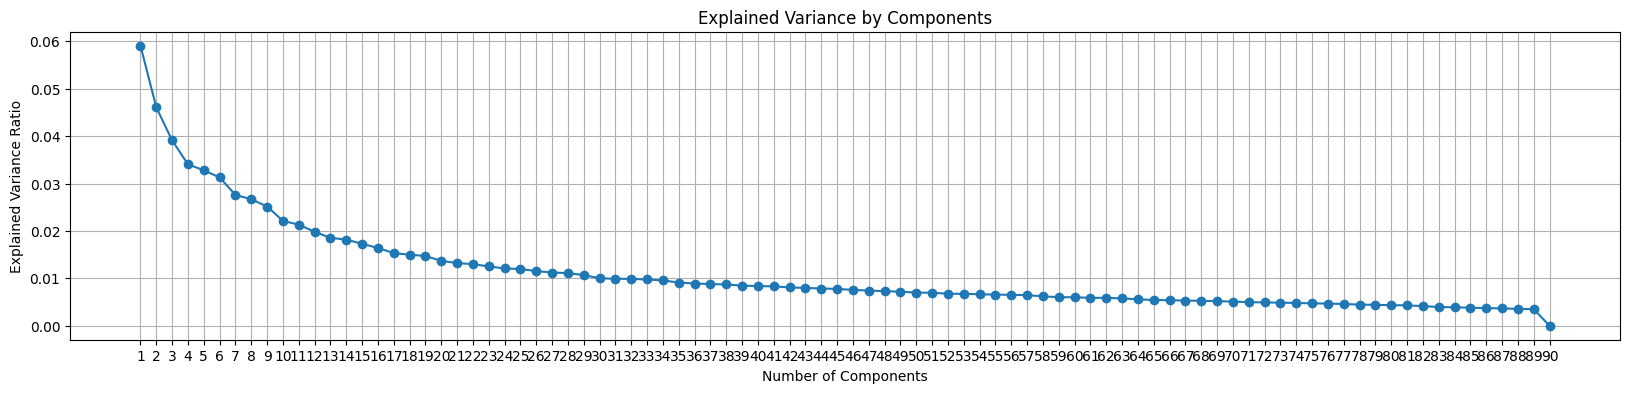

In [71]:
pca = PCA()
pca.fit(normalized_features_no_missing)

# Get the explained variance ratio
explained_variance = pca.explained_variance_ratio_

# Plotting the explained variance
plt.figure(figsize=(20, 4))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o')
plt.title('Explained Variance by Components')
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance Ratio')
plt.xticks(range(1, len(explained_variance) + 1))  # Ensure x-ticks match the number of components
plt.grid(True)
plt.show()

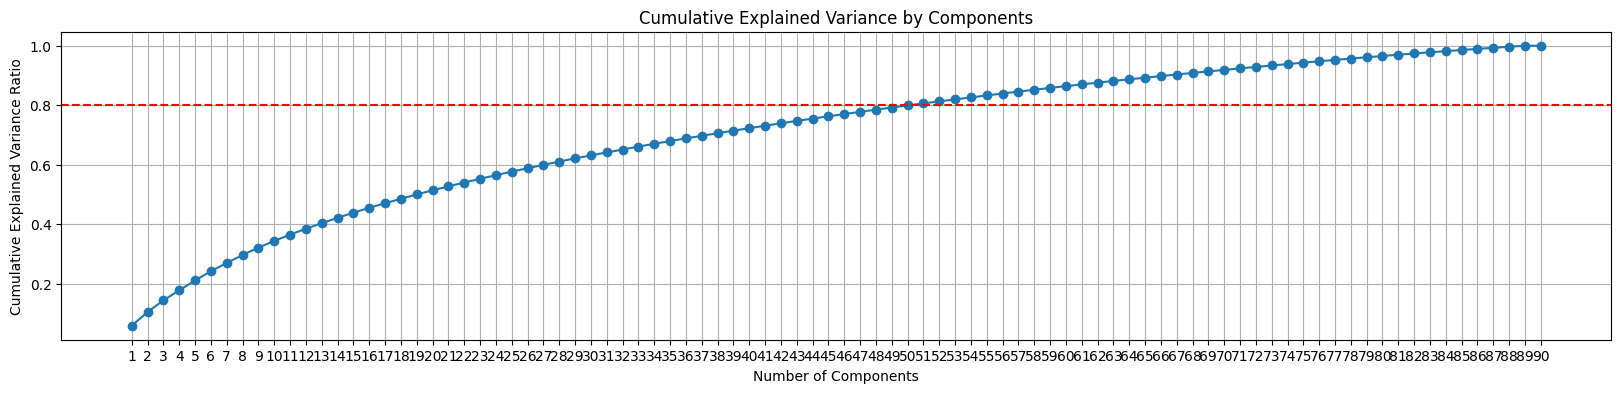

In [72]:
# cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

cumulative_variance = np.cumsum(explained_variance)
# Plotting the cumulative explained variance
plt.figure(figsize=(20, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.title('Cumulative Explained Variance by Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.xticks(range(1, len(cumulative_variance) + 1)) 
plt.grid(True)
plt.axhline(y=0.8, color='r', linestyle='--')
plt.show()

#### Volcano plot

In [73]:
omics_df_vol = omics_demo_normalise_df_no_missing.copy()
condition_H = omics_df_vol[omics_df_vol['label'] == 1].drop(columns='label')
condition_N = omics_df_vol[omics_df_vol['label'] == 0].drop(columns='label')
log2_fold_changes = []
p_values = []

for feature in condition_H.columns:
    mean_H = condition_H[feature].mean()
    mean_N = condition_N[feature].mean()
    log2_fc = np.log2(mean_H / mean_N)
    log2_fold_changes.append(log2_fc)
    
    # T-test
    _, p_value = ttest_ind(condition_H[feature], condition_N[feature])
    p_values.append(p_value)

# Create a DataFrame for the results
results_df = pd.DataFrame({
    'feature': condition_H.columns,
    'log2FoldChange': log2_fold_changes,
    'pvalue': p_values
})

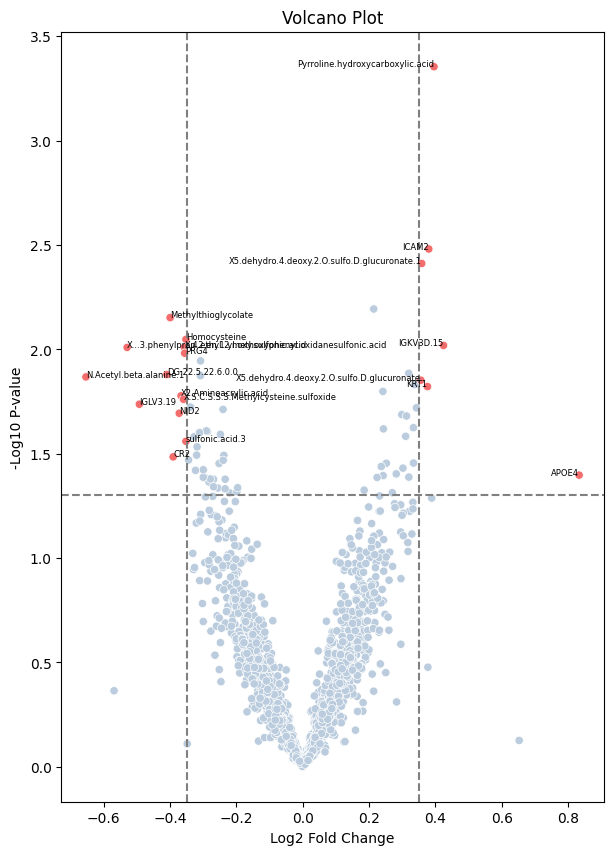

In [74]:
pvalue_threshold = 0.05
log2fc_threshold = 0.35

# Create a new column to define colors based on significance
results_df['color'] = '#BACCDD'  # Not significant
results_df.loc[(results_df['pvalue'] < pvalue_threshold) & (abs(results_df['log2FoldChange']) > log2fc_threshold), 'color'] = '#F46D6D'

plt.figure(figsize=(7, 10))
sns.scatterplot(x='log2FoldChange', y=-np.log10(results_df['pvalue']), data=results_df, hue='color', palette={'#BACCDD': '#BACCDD', '#F46D6D': '#F46D6D'}, legend=False)
plt.xlabel('Log2 Fold Change')
plt.ylabel('-Log10 P-value')
plt.title('Volcano Plot')

# Add threshold lines
plt.axhline(-np.log10(pvalue_threshold), color='gray', linestyle='--')
plt.axvline(log2fc_threshold, color='gray', linestyle='--')
plt.axvline(-log2fc_threshold, color='gray', linestyle='--')

# Annotate significant points
for i, row in results_df.iterrows():
    if row['color'] == '#F46D6D':
        ha = 'right' if row['log2FoldChange'] > log2fc_threshold else 'left'
        plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha=ha)

# for i, row in results_df.iterrows():
#     if row['color'] == '#DDBABA':
#         plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha='left')
plt.savefig("../plots/volcano_plot.png", bbox_inches='tight')
plt.show()


In [75]:
df_sorted = results_df.sort_values(by='pvalue', ascending=True)
df_sorted.head(10)

,feature,log2FoldChange,pvalue,color
115,Pyrroline.hydroxycarboxylic.acid,0.395401,0.000442,#F46D6D
1603,ICAM2,0.379777,0.003302,#F46D6D
721,X5.dehydro.4.deoxy.2.O.sulfo.D.glucuronate.1,0.358491,0.003874,#F46D6D
9,Butyric.acid.1,0.213959,0.006402,#BACCDD
231,Methylthioglycolate,-0.399415,0.007044,#F46D6D
159,Homocysteine,-0.351756,0.008954,#F46D6D
1670,IGKV3D.15,0.424186,0.009571,#F46D6D
635,X.4.ethyl.2.methoxyphenyl.oxidanesulfonic.acid,-0.356825,0.009765,#F46D6D
548,X...3.phenylprop.2.en.1.yl.oxy.sulfonic.acid,-0.528927,0.009782,#F46D6D
1831,PRG4,-0.355534,0.010427,#F46D6D


In [76]:
results_df[results_df['feature']=='APOE4']

,feature,log2FoldChange,pvalue,color
1945,APOE4,0.832649,0.04002,#F46D6D


#### Heatmap

In [77]:
feature_type_df = pd.read_csv('../data/merged_data/feature_type.csv',index_col=0)
result_for_heatmap = pd.merge(results_df, feature_type_df, on=['feature'],how='inner')

<Figure size 1400x1000 with 0 Axes>

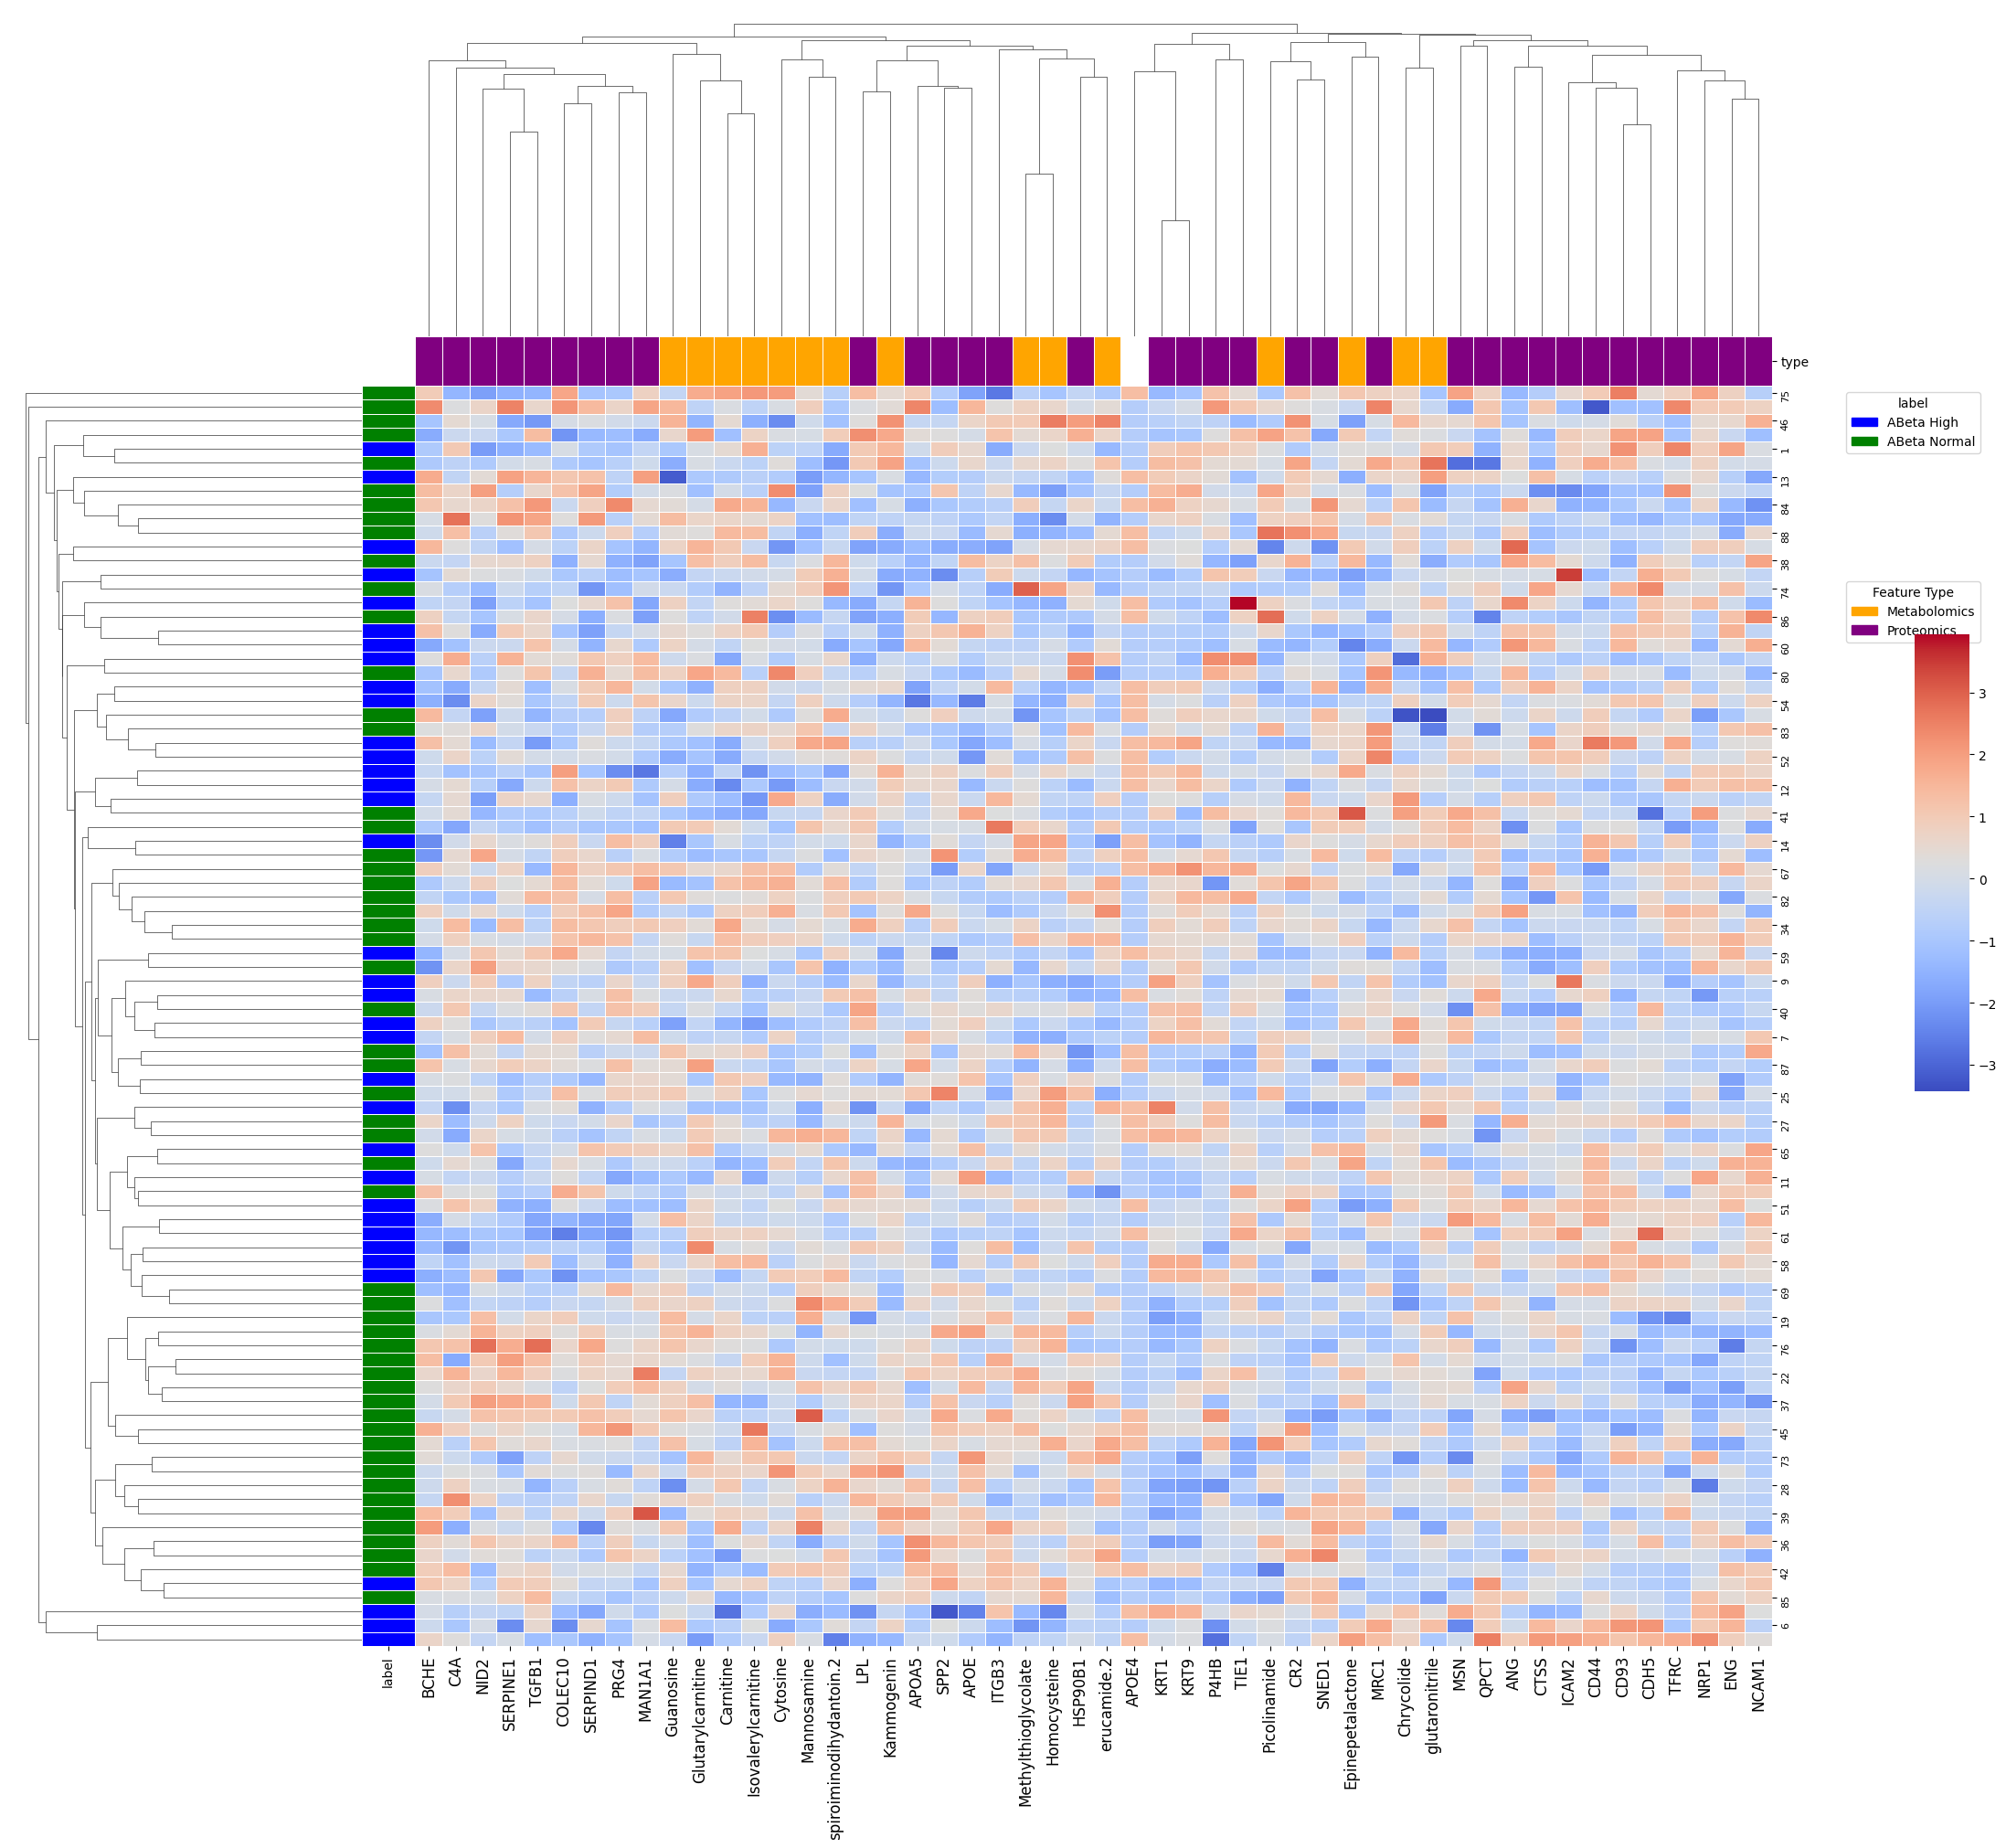

In [78]:
top_50_features = result_for_heatmap.nsmallest(50, 'pvalue')['feature'].values
heatmap_data = omics_df_vol[top_50_features]
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()

# Add a condition column to heatmap_data for annotation
omics_df_vol['label']=omics_df_vol['label'].replace({1: 'ABeta High', 0: 'ABeta Normal'})
heatmap_data['label'] = omics_df_vol['label']

# Reorder the columns to move 'condition' to the beginning
cols = heatmap_data.columns.tolist()
cols = cols[-1:] + cols[:-1]
heatmap_data = heatmap_data[cols]

# Create a color bar for the feature types
feature_types = result_for_heatmap.set_index('feature').loc[top_50_features, 'type']
feature_type_colors = feature_types.map({'metabolomics': 'orange', 'proteomics': 'purple'})


plt.figure(figsize=(14, 10))

# Create row and column linkage matrices for clustering
row_linkage = linkage(heatmap_data.drop(columns='label'), method='average')
col_linkage = linkage(heatmap_data.drop(columns='label').T, method='average')

# Create the clustermap
g = sns.clustermap(
    heatmap_data.drop(columns='label'), 
    row_linkage=row_linkage, 
    col_linkage=col_linkage, 
    cmap='coolwarm', 
    linewidths=0.5,
    figsize=(20, 20),
    row_colors=heatmap_data['label'].map({'ABeta High': 'blue', 'ABeta Normal': 'green'}),
    col_colors=feature_type_colors,
    cbar_pos=(1.05, 0.4, 0.03, 0.25)  # Adjusting colorbar position
)

g.ax_heatmap.tick_params(axis='x', labelsize=12)
g.ax_heatmap.tick_params(axis='y', labelsize=8)

# Create legend handles
condition_legend = [Patch(facecolor='blue', edgecolor='blue', label='ABeta High'),
                    Patch(facecolor='green', edgecolor='green', label='ABeta Normal')]
feature_type_legend = [Patch(facecolor='orange', edgecolor='orange', label='Metabolomics'),
                       Patch(facecolor='purple', edgecolor='purple', label='Proteomics')]

# Add legends to the plot
legend1 = g.ax_heatmap.legend(handles=condition_legend, title='label', loc='upper left', bbox_to_anchor=(1.05, 1))
legend2 = g.ax_heatmap.legend(handles=feature_type_legend, title='Feature Type', loc='upper left', bbox_to_anchor=(1.05, 0.85))

# Add both legends to the plot
g.ax_heatmap.add_artist(legend1)
plt.savefig("../plots/heatmap.png", bbox_inches='tight')
plt.show()

<Figure size 1400x1000 with 0 Axes>

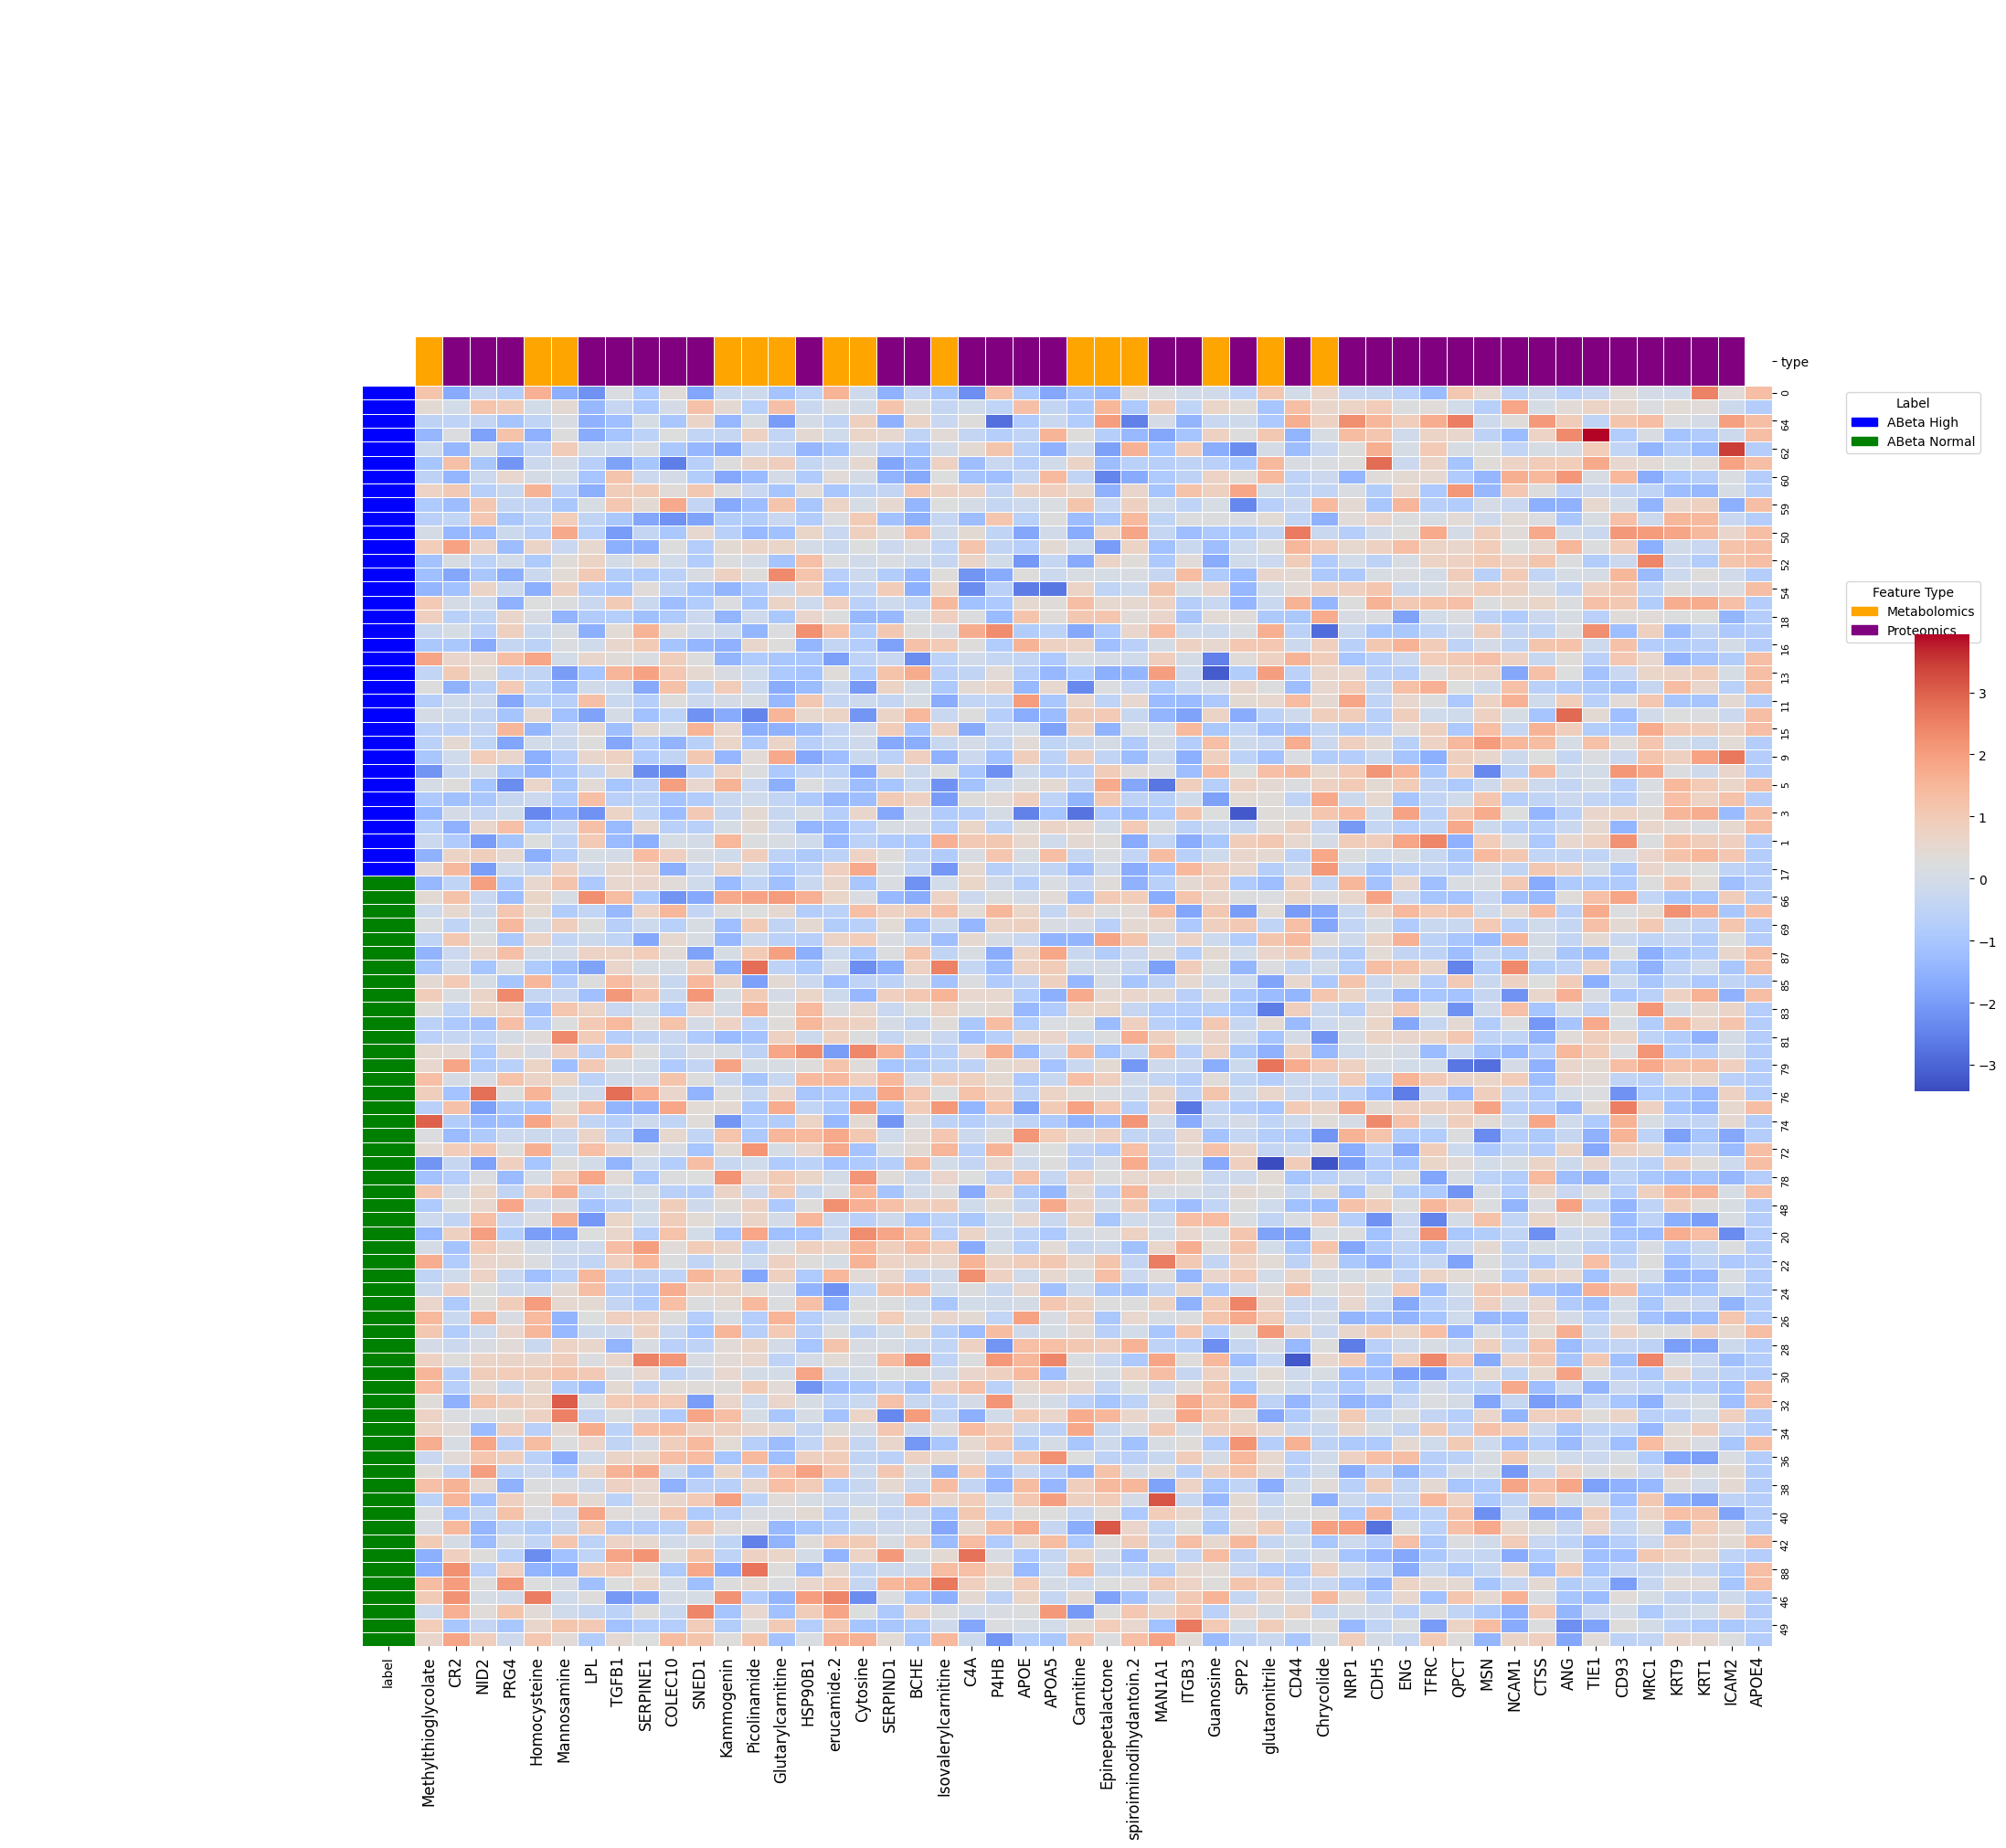

In [80]:
# Select the top 50 features by p-value
top_50_features = result_for_heatmap.nsmallest(50, 'pvalue')

# Sort these features from downregulation to upregulation by fold change
top_50_features_sorted = top_50_features.sort_values(by='log2FoldChange')

# Get the sorted feature names
sorted_feature_names = top_50_features_sorted['feature'].values

# Extract the heatmap data for these sorted features
heatmap_data = omics_df_vol[sorted_feature_names]
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()

# Update label for clarity in annotation
omics_df_vol['label'] = omics_df_vol['label'].replace({1: 'ABeta High', 0: 'ABeta Normal'})
heatmap_data['label'] = omics_df_vol['label']

# Reordering columns to move 'label' to the beginning for better visibility
cols = heatmap_data.columns.tolist()
cols = cols[-1:] + cols[:-1]
heatmap_data = heatmap_data[cols]
heatmap_data = heatmap_data.sort_values(by='label')

# Defining feature type colors
feature_types = result_for_heatmap.set_index('feature').loc[sorted_feature_names, 'type']
feature_type_colors = feature_types.map({'metabolomics': 'orange', 'proteomics': 'purple'})

plt.figure(figsize=(14, 10))

# Clustering
row_linkage = linkage(heatmap_data.drop(columns='label'), method='average')
col_linkage = linkage(heatmap_data.drop(columns='label').T, method='average')

# Generating clustermap
g = sns.clustermap(
    heatmap_data.drop(columns='label'),
    col_cluster=False,  # Already set to maintain column order
    row_cluster=False,  # Disable row clustering to maintain label sort order
    cmap='coolwarm',
    linewidths=0.5,
    figsize=(20, 20),
    row_colors=heatmap_data['label'].map({'ABeta High': 'blue', 'ABeta Normal': 'green'}),
    col_colors=feature_type_colors,
    cbar_pos=(1.05, 0.4, 0.03, 0.25)
)

# Adjusting tick parameters for better readability
g.ax_heatmap.tick_params(axis='x', labelsize=12)
g.ax_heatmap.tick_params(axis='y', labelsize=8)

# Creating legends for conditions and feature types
condition_legend = [Patch(facecolor='blue', edgecolor='blue', label='ABeta High'),
                    Patch(facecolor='green', edgecolor='green', label='ABeta Normal')]
feature_type_legend = [Patch(facecolor='orange', edgecolor='orange', label='Metabolomics'),
                       Patch(facecolor='purple', edgecolor='purple', label='Proteomics')]

# Adding legends to the plot
legend1 = g.ax_heatmap.legend(handles=condition_legend, title='Label', loc='upper left', bbox_to_anchor=(1.05, 1))
legend2 = g.ax_heatmap.legend(handles=feature_type_legend, title='Feature Type', loc='upper left', bbox_to_anchor=(1.05, 0.85))

# Ensuring both legends are added
g.ax_heatmap.add_artist(legend1)
plt.show()


In [81]:
top_50_features = result_for_heatmap.nsmallest(50, 'pvalue')['feature'].values
top_50_features = np.append(['label','Demographic.Sex'], top_50_features)
heatmap_data = omics_df_vol[top_50_features]
heatmap_data.to_csv("../statistics/heatmap_minimaxtop50.csv")


In [82]:
top_50_features

array(['label', 'Demographic.Sex', 'ICAM2', 'Methylthioglycolate',
       'Homocysteine', 'PRG4', 'COLEC10', 'KRT1', 'LPL', 'NID2', 'MSN',
       'Picolinamide', 'SERPINE1', 'CD93', 'CR2', 'Mannosamine', 'P4HB',
       'QPCT', 'SNED1', 'TGFB1', 'ANG', 'APOE4', 'KRT9', 'CDH5',
       'Carnitine', 'SERPIND1', 'SPP2', 'APOA5', 'Chrycolide',
       'Guanosine', 'CTSS', 'ENG', 'Cytosine', 'Kammogenin', 'APOE',
       'HSP90B1', 'TFRC', 'MAN1A1', 'erucamide.2', 'TIE1', 'BCHE',
       'glutaronitrile', 'ITGB3', 'C4A', 'Glutarylcarnitine',
       'Epinepetalactone', 'spiroiminodihydantoin.2', 'CD44',
       'Isovalerylcarnitine', 'NCAM1', 'NRP1', 'MRC1'], dtype=object)

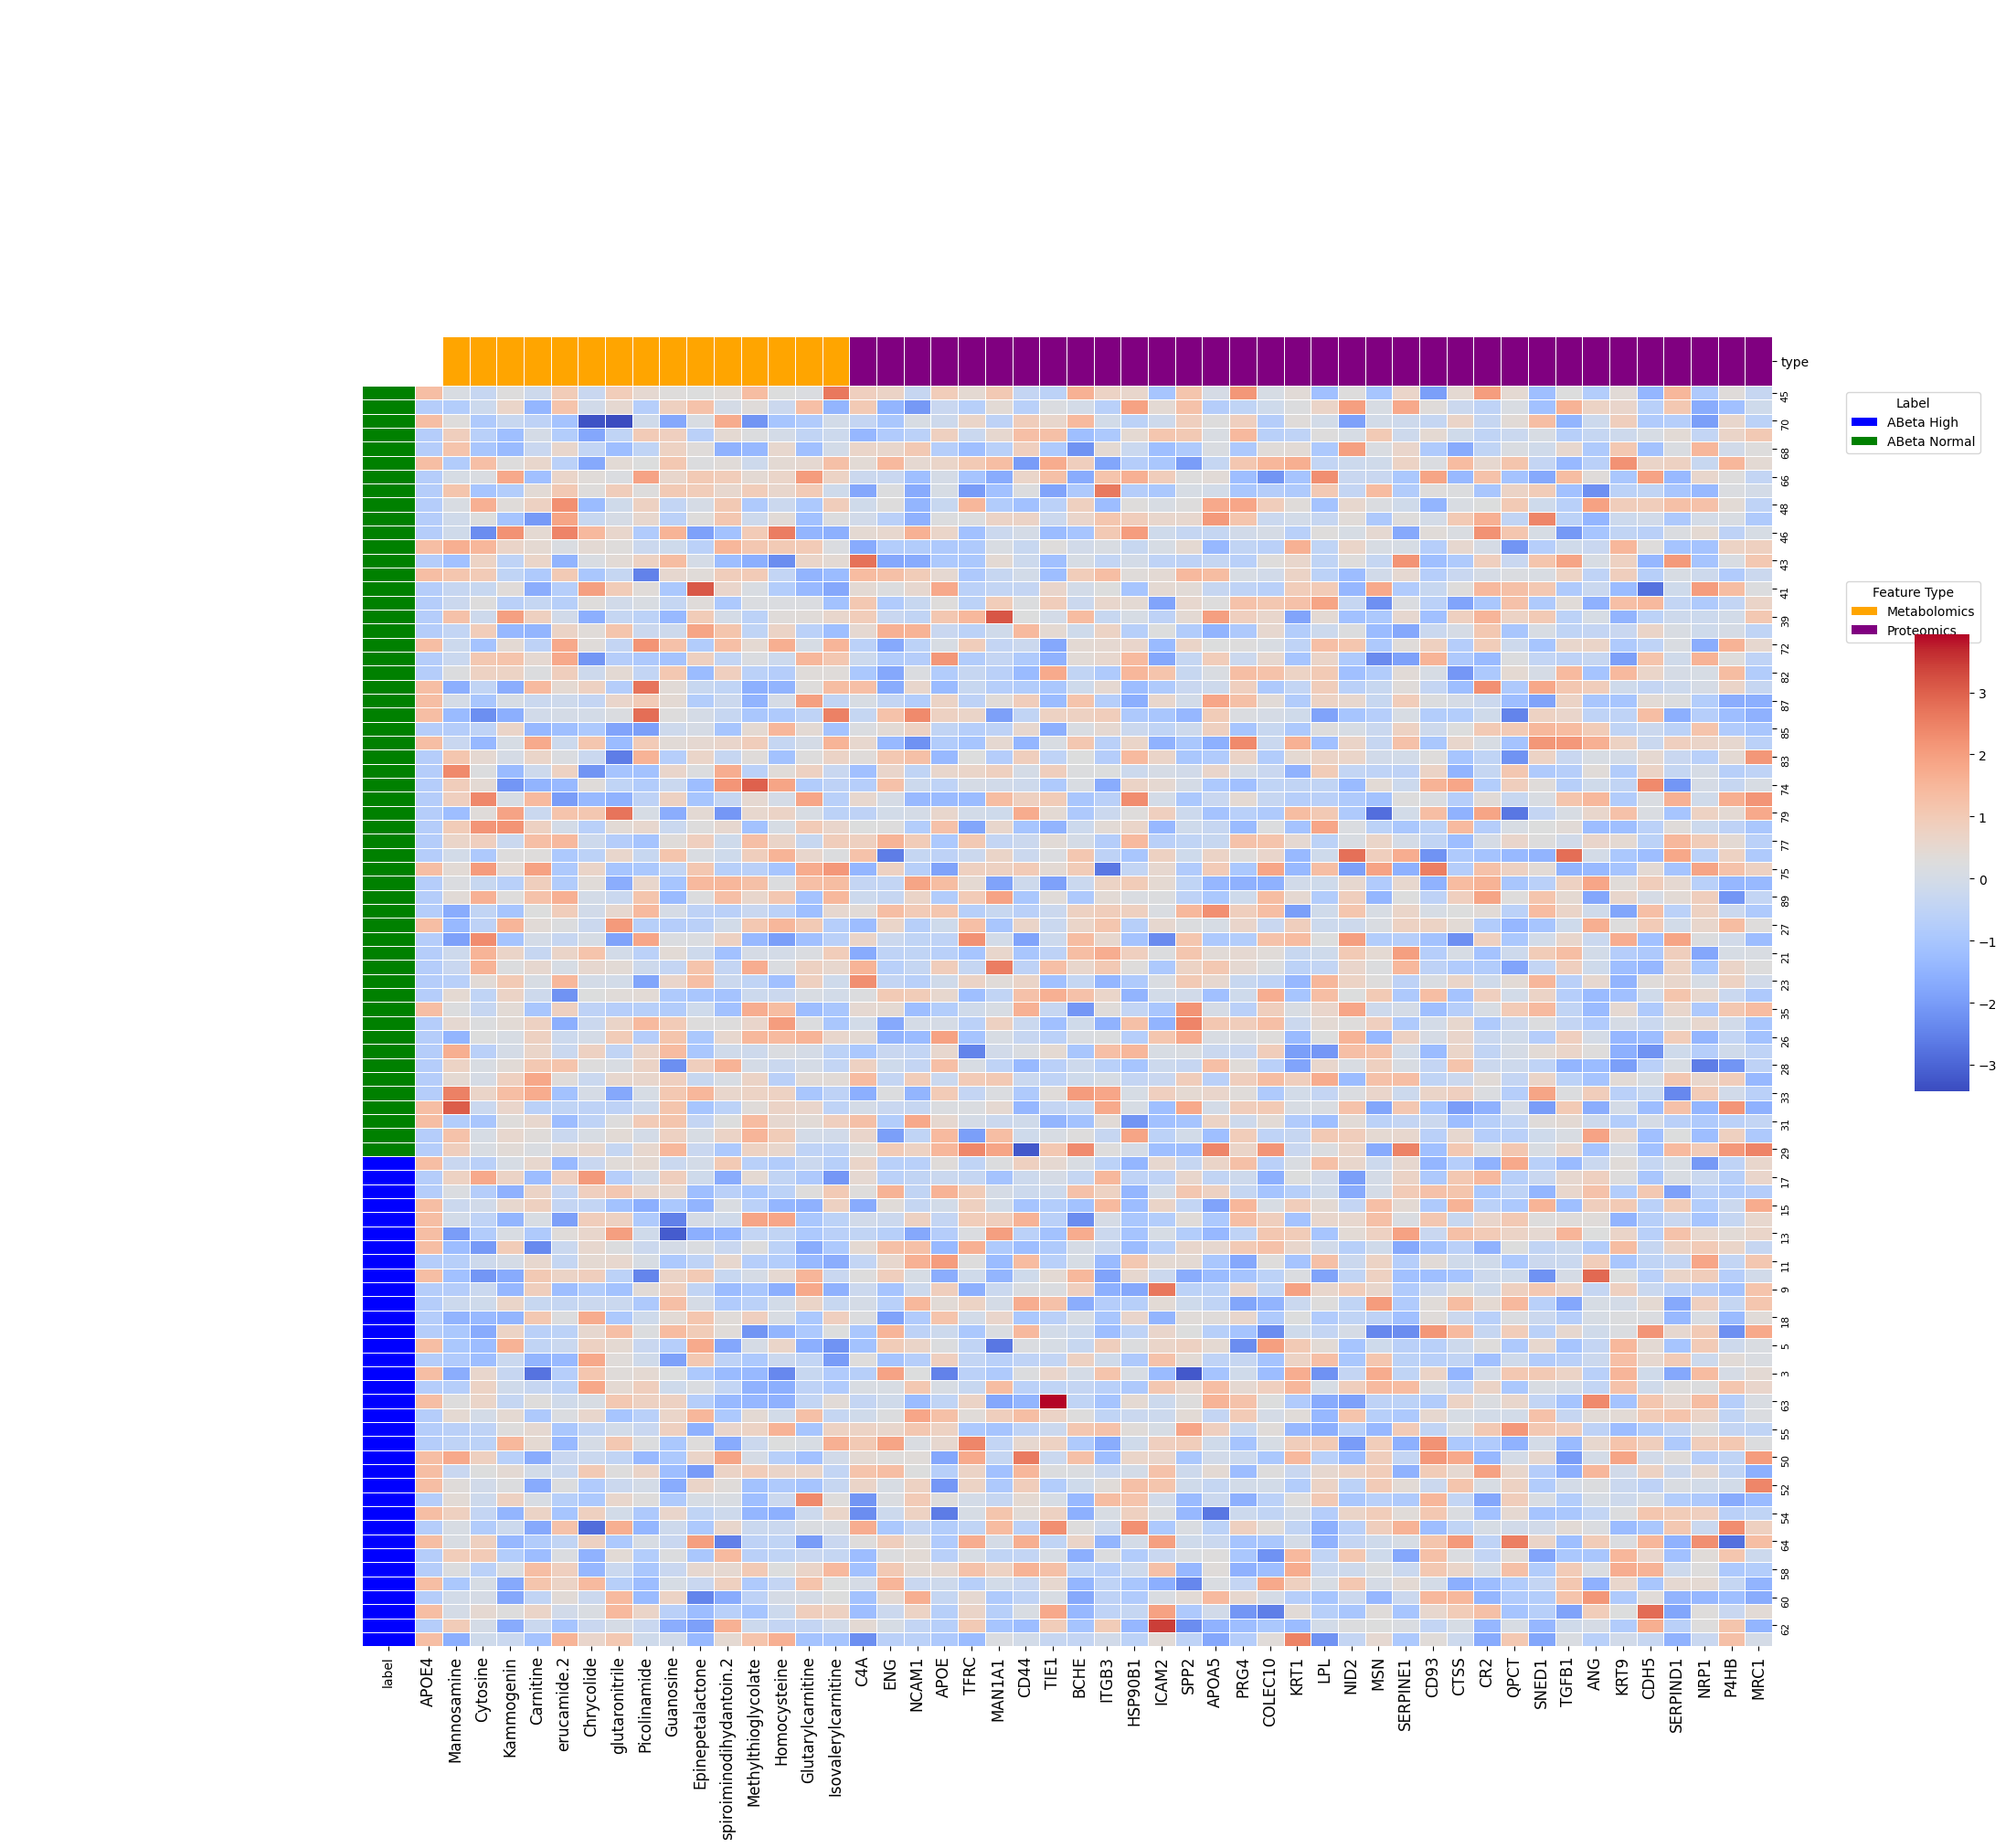

In [83]:
omics_df_vol['label'] = omics_df_vol['label'].replace({1: 'ABeta High', 0: 'ABeta Normal'})

# Selecting top 50 features and normalizing data
top_50_features = result_for_heatmap.nsmallest(50, 'pvalue')['feature'].values
heatmap_data = omics_df_vol[top_50_features]
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()
heatmap_data['label'] = omics_df_vol['label']

# Sorting data by labels and feature types
heatmap_data = heatmap_data.sort_values('label', ascending=False)  # Adjust based on your label order
feature_types = result_for_heatmap.set_index('feature').loc[top_50_features, 'type'].sort_values()
heatmap_data = heatmap_data[feature_types.index.tolist() + ['label']]

# Color mapping
feature_type_colors = feature_types.map({'metabolomics': 'orange', 'proteomics': 'purple'}).loc[feature_types.index]

# Plotting without automatic clustering
g = sns.clustermap(
    heatmap_data.drop(columns='label'), 
    cmap='coolwarm', 
    linewidths=0.5,
    figsize=(20, 20),
    row_colors=heatmap_data['label'].map({'ABeta High': 'blue', 'ABeta Normal': 'green'}),
    col_colors=feature_type_colors,
    cbar_pos=(1.05, 0.4, 0.03, 0.25),
    row_cluster=False,  
    col_cluster=False   
)

# Adjusting ticks and adding legends
g.ax_heatmap.tick_params(axis='x', labelsize=12)
g.ax_heatmap.tick_params(axis='y', labelsize=8)
legend1 = g.ax_heatmap.legend(handles=[Patch(facecolor='blue', label='ABeta High'), Patch(facecolor='green', label='ABeta Normal')], title='Label', loc='upper left', bbox_to_anchor=(1.05, 1))
legend2 = g.ax_heatmap.legend(handles=[Patch(facecolor='orange', label='Metabolomics'), Patch(facecolor='purple', label='Proteomics')], title='Feature Type', loc='upper left', bbox_to_anchor=(1.05, 0.85))

# Ensure legends are displayed
g.ax_heatmap.add_artist(legend1)
plt.savefig("../plots/heatmap2.png", bbox_inches='tight')
plt.show()


In [84]:
omics_df_vol_F = omics_demo_normalise_df_no_missing[omics_demo_normalise_df_no_missing['Demographic.Sex']==0]
condition_H_F = omics_df_vol_F[omics_df_vol_F['label'] == 1].drop(columns='label')
condition_N_F = omics_df_vol_F[omics_df_vol_F['label'] == 0].drop(columns='label')
log2_fold_changes_F = []
p_values_F = []

for feature_F in condition_H_F.columns:
    mean_H_F = condition_H_F[feature_F].mean()
    mean_N_F = condition_N_F[feature_F].mean()
    log2_fc_F = np.log2(mean_H_F / mean_N_F)
    log2_fold_changes_F.append(log2_fc_F)
    
    # T-test
    _, p_value_F = ttest_ind(condition_H_F[feature_F], condition_N_F[feature_F])
    p_values_F.append(p_value_F)

# Create a DataFrame for the results
results_df_F = pd.DataFrame({
    'feature': condition_H_F.columns,
    'log2FoldChange': log2_fold_changes_F,
    'pvalue': p_values_F
})

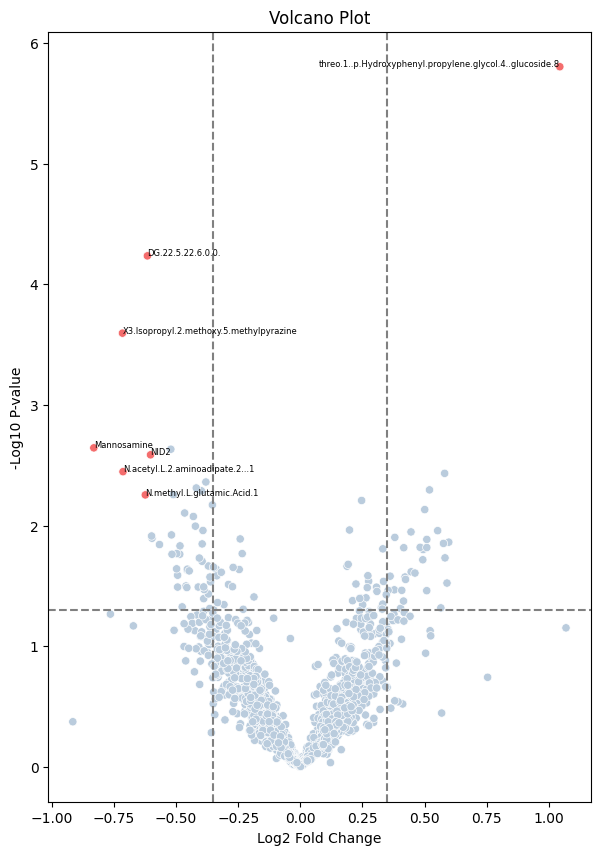

In [85]:
# Create a new column to define colors based on significance
results_df_F['color'] = '#BACCDD'  # Not significant
results_df_F.loc[(results_df_F['pvalue'] < pvalue_threshold) & (abs(results_df_F['log2FoldChange']) > 0.6), 'color'] = '#F46D6D'

# Create plot
plt.figure(figsize=(7, 10))
sns.scatterplot(x='log2FoldChange', y=-np.log10(results_df_F['pvalue']), data=results_df_F, hue='color', palette={'#BACCDD': '#BACCDD', '#F46D6D': '#F46D6D'}, legend=False)
plt.xlabel('Log2 Fold Change')
plt.ylabel('-Log10 P-value')
plt.title('Volcano Plot')

# Add threshold lines
plt.axhline(-np.log10(pvalue_threshold), color='gray', linestyle='--')
plt.axvline(log2fc_threshold, color='gray', linestyle='--')
plt.axvline(-log2fc_threshold, color='gray', linestyle='--')

# Annotate significant points
for i, row in results_df_F.iterrows():
    if row['color'] == '#F46D6D':
        ha = 'right' if row['log2FoldChange'] > log2fc_threshold else 'left'
        plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha=ha)

# for i, row in results_df.iterrows():
#     if row['color'] == '#DDBABA':
#         plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha='left')
plt.show()

In [86]:
df_sorted_F = results_df_F.sort_values(by='pvalue', ascending=True)
df_sorted_F.head(20)

,feature,log2FoldChange,pvalue,color
1045,threo.1..p.Hydroxyphenyl.propylene.glycol.4..g...,1.043967,0.000002,#F46D6D
1324,DG.22.5.22.6.0.0.,-0.615272,0.000058,#F46D6D
304,X3.Isopropyl.2.methoxy.5.methylpyrazine,-0.715519,0.000254,#F46D6D
374,Mannosamine,-0.830726,0.002270,#F46D6D
459,Quinic.acid,-0.520951,0.002330,#BACCDD
1780,NID2,-0.602584,0.002593,#F46D6D
511,N.acetyl.L.2.aminoadipate.2...1,-0.713425,0.003577,#F46D6D
1768,MRC1,0.580663,0.003693,#BACCDD
581,D.galactopyranosyl.trimethylammonium.bromide,-0.380007,0.004356,#BACCDD
1822,PON1,-0.418510,0.004882,#BACCDD


In [87]:
result_for_heatmap_F = pd.merge(results_df_F, feature_type_df, on=['feature'],how='inner')
top_20_features_F = result_for_heatmap_F.nsmallest(20, 'pvalue')['feature'].values

In [89]:
omics_df_vol_M = omics_demo_normalise_df_no_missing[omics_demo_normalise_df_no_missing['Demographic.Sex']==1]
condition_H_M = omics_df_vol_M[omics_df_vol_M['label'] == 1].drop(columns='label')
condition_N_M = omics_df_vol_M[omics_df_vol_M['label'] == 0].drop(columns='label')
log2_fold_changes_M = []
p_values_M = []

for feature_M in condition_H_M.columns:
    mean_H_M = condition_H_M[feature_M].mean()
    mean_N_M = condition_N_M[feature_M].mean()
    log2_fc_M = np.log2(mean_H_M / mean_N_M)
    log2_fold_changes_M.append(log2_fc_M)
    
    # T-test
    _, p_value_M = ttest_ind(condition_H_M[feature_M], condition_N_M[feature_M])
    p_values_M.append(p_value_M)

# Create a DataFrame for the results
results_df_M = pd.DataFrame({
    'feature': condition_H_M.columns,
    'log2FoldChange': log2_fold_changes_M,
    'pvalue': p_values_M
})

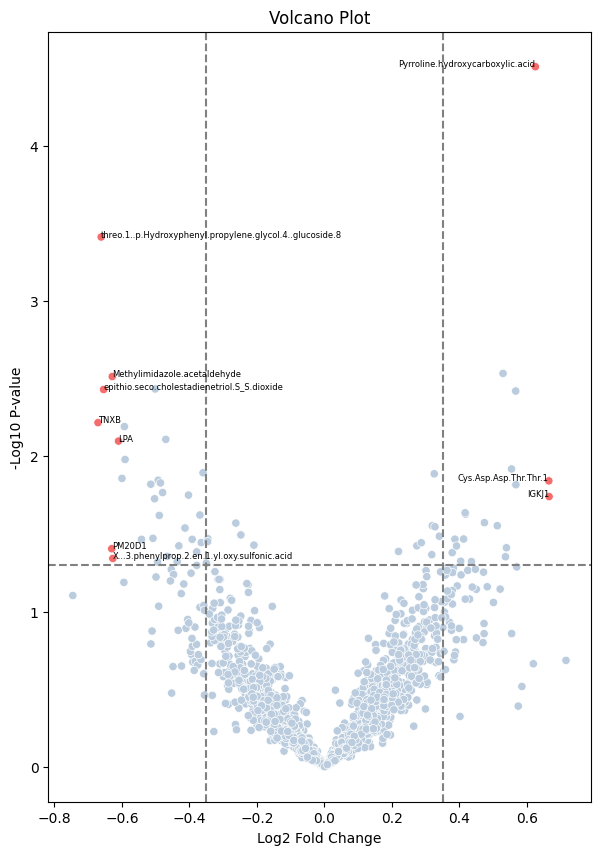

In [90]:
# Create a new column to define colors based on significance
results_df_M['color'] = '#BACCDD'  # Not significant
results_df_M.loc[(results_df_M['pvalue'] < pvalue_threshold) & (abs(results_df_M['log2FoldChange']) > 0.6), 'color'] = '#F46D6D'

# Create plot
plt.figure(figsize=(7, 10))
sns.scatterplot(x='log2FoldChange', y=-np.log10(results_df_M['pvalue']), data=results_df_M, hue='color', palette={'#BACCDD': '#BACCDD', '#F46D6D': '#F46D6D'}, legend=False)
plt.xlabel('Log2 Fold Change')
plt.ylabel('-Log10 P-value')
plt.title('Volcano Plot')

# Add threshold lines
plt.axhline(-np.log10(pvalue_threshold), color='gray', linestyle='--')
plt.axvline(log2fc_threshold, color='gray', linestyle='--')
plt.axvline(-log2fc_threshold, color='gray', linestyle='--')

# Annotate significant points
for i, row in results_df_M.iterrows():
    if row['color'] == '#F46D6D':
        ha = 'right' if row['log2FoldChange'] > log2fc_threshold else 'left'
        plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha=ha)

# for i, row in results_df.iterrows():
#     if row['color'] == '#DDBABA':
#         plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha='left')
plt.show()

In [91]:
df_sorted_M = results_df_M.sort_values(by='pvalue', ascending=True)
df_sorted_M.head(20)

,feature,log2FoldChange,pvalue,color
115,Pyrroline.hydroxycarboxylic.acid,0.624866,0.000031,#F46D6D
1045,threo.1..p.Hydroxyphenyl.propylene.glycol.4..g...,-0.661376,0.000386,#F46D6D
1791,OMD,0.529048,0.002923,#BACCDD
91,Methylimidazole.acetaldehyde,-0.628591,0.003061,#F46D6D
765,cyclopentanehexanoic.acid,-0.501308,0.003680,#BACCDD
1197,epithio.seco.cholestadienetriol.S_S.dioxide,-0.654128,0.003711,#F46D6D
1119,Citroside.A.4,0.566640,0.003795,#BACCDD
1925,TNXB,-0.670804,0.006066,#F46D6D
1220,X6beta.acetoxy.24.methylcholestan.3beta_5alpha...,-0.592663,0.006429,#BACCDD
1237,X7beta.acetoxy.gorgostan.3beta_5alpha_6beta.triol,-0.469898,0.007773,#BACCDD


In [92]:
result_for_heatmap_M = pd.merge(results_df_M, feature_type_df, on=['feature'],how='inner')
top_20_features_M = result_for_heatmap_M.nsmallest(20, 'pvalue')['feature'].values

In [101]:
combined_array = np.unique(np.concatenate((top_20_features_M, top_20_features_F)))
top_40_features = np.append(['label','Demographic.Sex'], combined_array)
heatmap_data = omics_df_vol[top_40_features]
heatmap_data

,label,Demographic.Sex,APOA5,C8A,CACNA2D1,CDHR5,CFHR2,CTSS,Chrycolide,Cytosine,...,PON1,SPP2,SRGN,STAB1,TFRC,TLN1,TNXB,Tridecanamide,diazaborine,spiroiminodihydantoin.2
0,ABeta High,0,0.181659,0.860082,0.098175,0.855876,0.424466,0.470130,0.726659,0.459676,...,0.569032,0.478506,0.669604,0.755431,0.240361,0.422850,0.369682,0.534613,0.686715,0.637638
1,ABeta High,0,0.503241,0.839070,0.631673,0.207668,0.849258,0.305789,0.623634,0.371036,...,0.591964,0.727999,0.423265,0.198166,1.000000,0.251704,0.514329,0.635599,0.561457,0.178097
2,ABeta High,0,0.657412,0.398815,0.131759,0.313375,0.944235,0.353590,0.561717,0.359186,...,0.436181,0.506854,0.538327,0.245103,0.405692,0.550692,0.272707,0.442292,0.915707,0.752815
3,ABeta High,0,0.322251,0.461100,0.702307,0.457941,0.651131,0.186162,0.824861,0.614491,...,0.329611,0.000000,0.217054,0.453729,0.380824,0.590100,0.572628,0.489826,0.354999,0.252888
4,ABeta High,0,0.426565,0.529330,0.805352,0.725025,0.629105,0.415906,0.945896,0.226507,...,0.338108,0.639828,0.445689,0.567134,0.416702,0.408055,0.257818,0.440791,0.655656,0.419228
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,ABeta Normal,1,0.687391,0.421148,0.647775,0.711616,0.623326,0.573756,0.444592,0.381700,...,0.444449,0.537002,0.649755,0.470343,0.360307,0.470915,0.315705,0.358139,0.229251,0.316784
86,ABeta Normal,1,0.715682,0.358335,0.378077,0.289855,0.336182,0.336470,0.608714,0.008036,...,0.502809,0.321904,0.398457,0.387533,0.643432,0.587428,0.543348,0.588541,0.435254,0.465722
87,ABeta Normal,1,0.884657,0.499000,0.601372,0.660643,0.755636,0.527426,0.539357,0.280188,...,0.485126,0.561062,0.424314,0.648948,0.394299,0.255542,0.281867,0.546910,0.485313,0.491135
88,ABeta Normal,1,0.496343,0.334686,0.611256,0.503528,0.851088,0.234878,0.760486,0.395543,...,0.527384,0.517038,0.325670,0.546477,0.440211,0.417764,0.398127,0.525882,0.462832,0.430244


In [123]:
heatmap_data.to_csv("heatmap_top40feature_gender.csv")

#### Violin plot

In [93]:
boxplot_df = omics_demo_normalise_df_no_missing.copy()
boxplot_df['label'] = boxplot_df['label'].replace({1:'High',  0:"Normal"})
boxplot_df['Demographic.Sex'] = boxplot_df['Demographic.Sex'].replace({1:"Male", 0: "Female"})
boxplot_df['APOE4'] = boxplot_df['APOE4'].replace({1:'Yes',  0:"No"})


hue_list = ['APOE4','Demographic.Sex','label']
boxplot_df[hue_list] = boxplot_df[hue_list].apply(lambda col: col.astype('category'))

In [108]:
[col for col in boxplot_df.columns if 'Isopropyl' in col]

['Isopropylmaleate',
 'X3.Isopropyl.2.methoxy.5.methylpyrazine',
 'X2.Isopropyl.3.oxosuccinate']

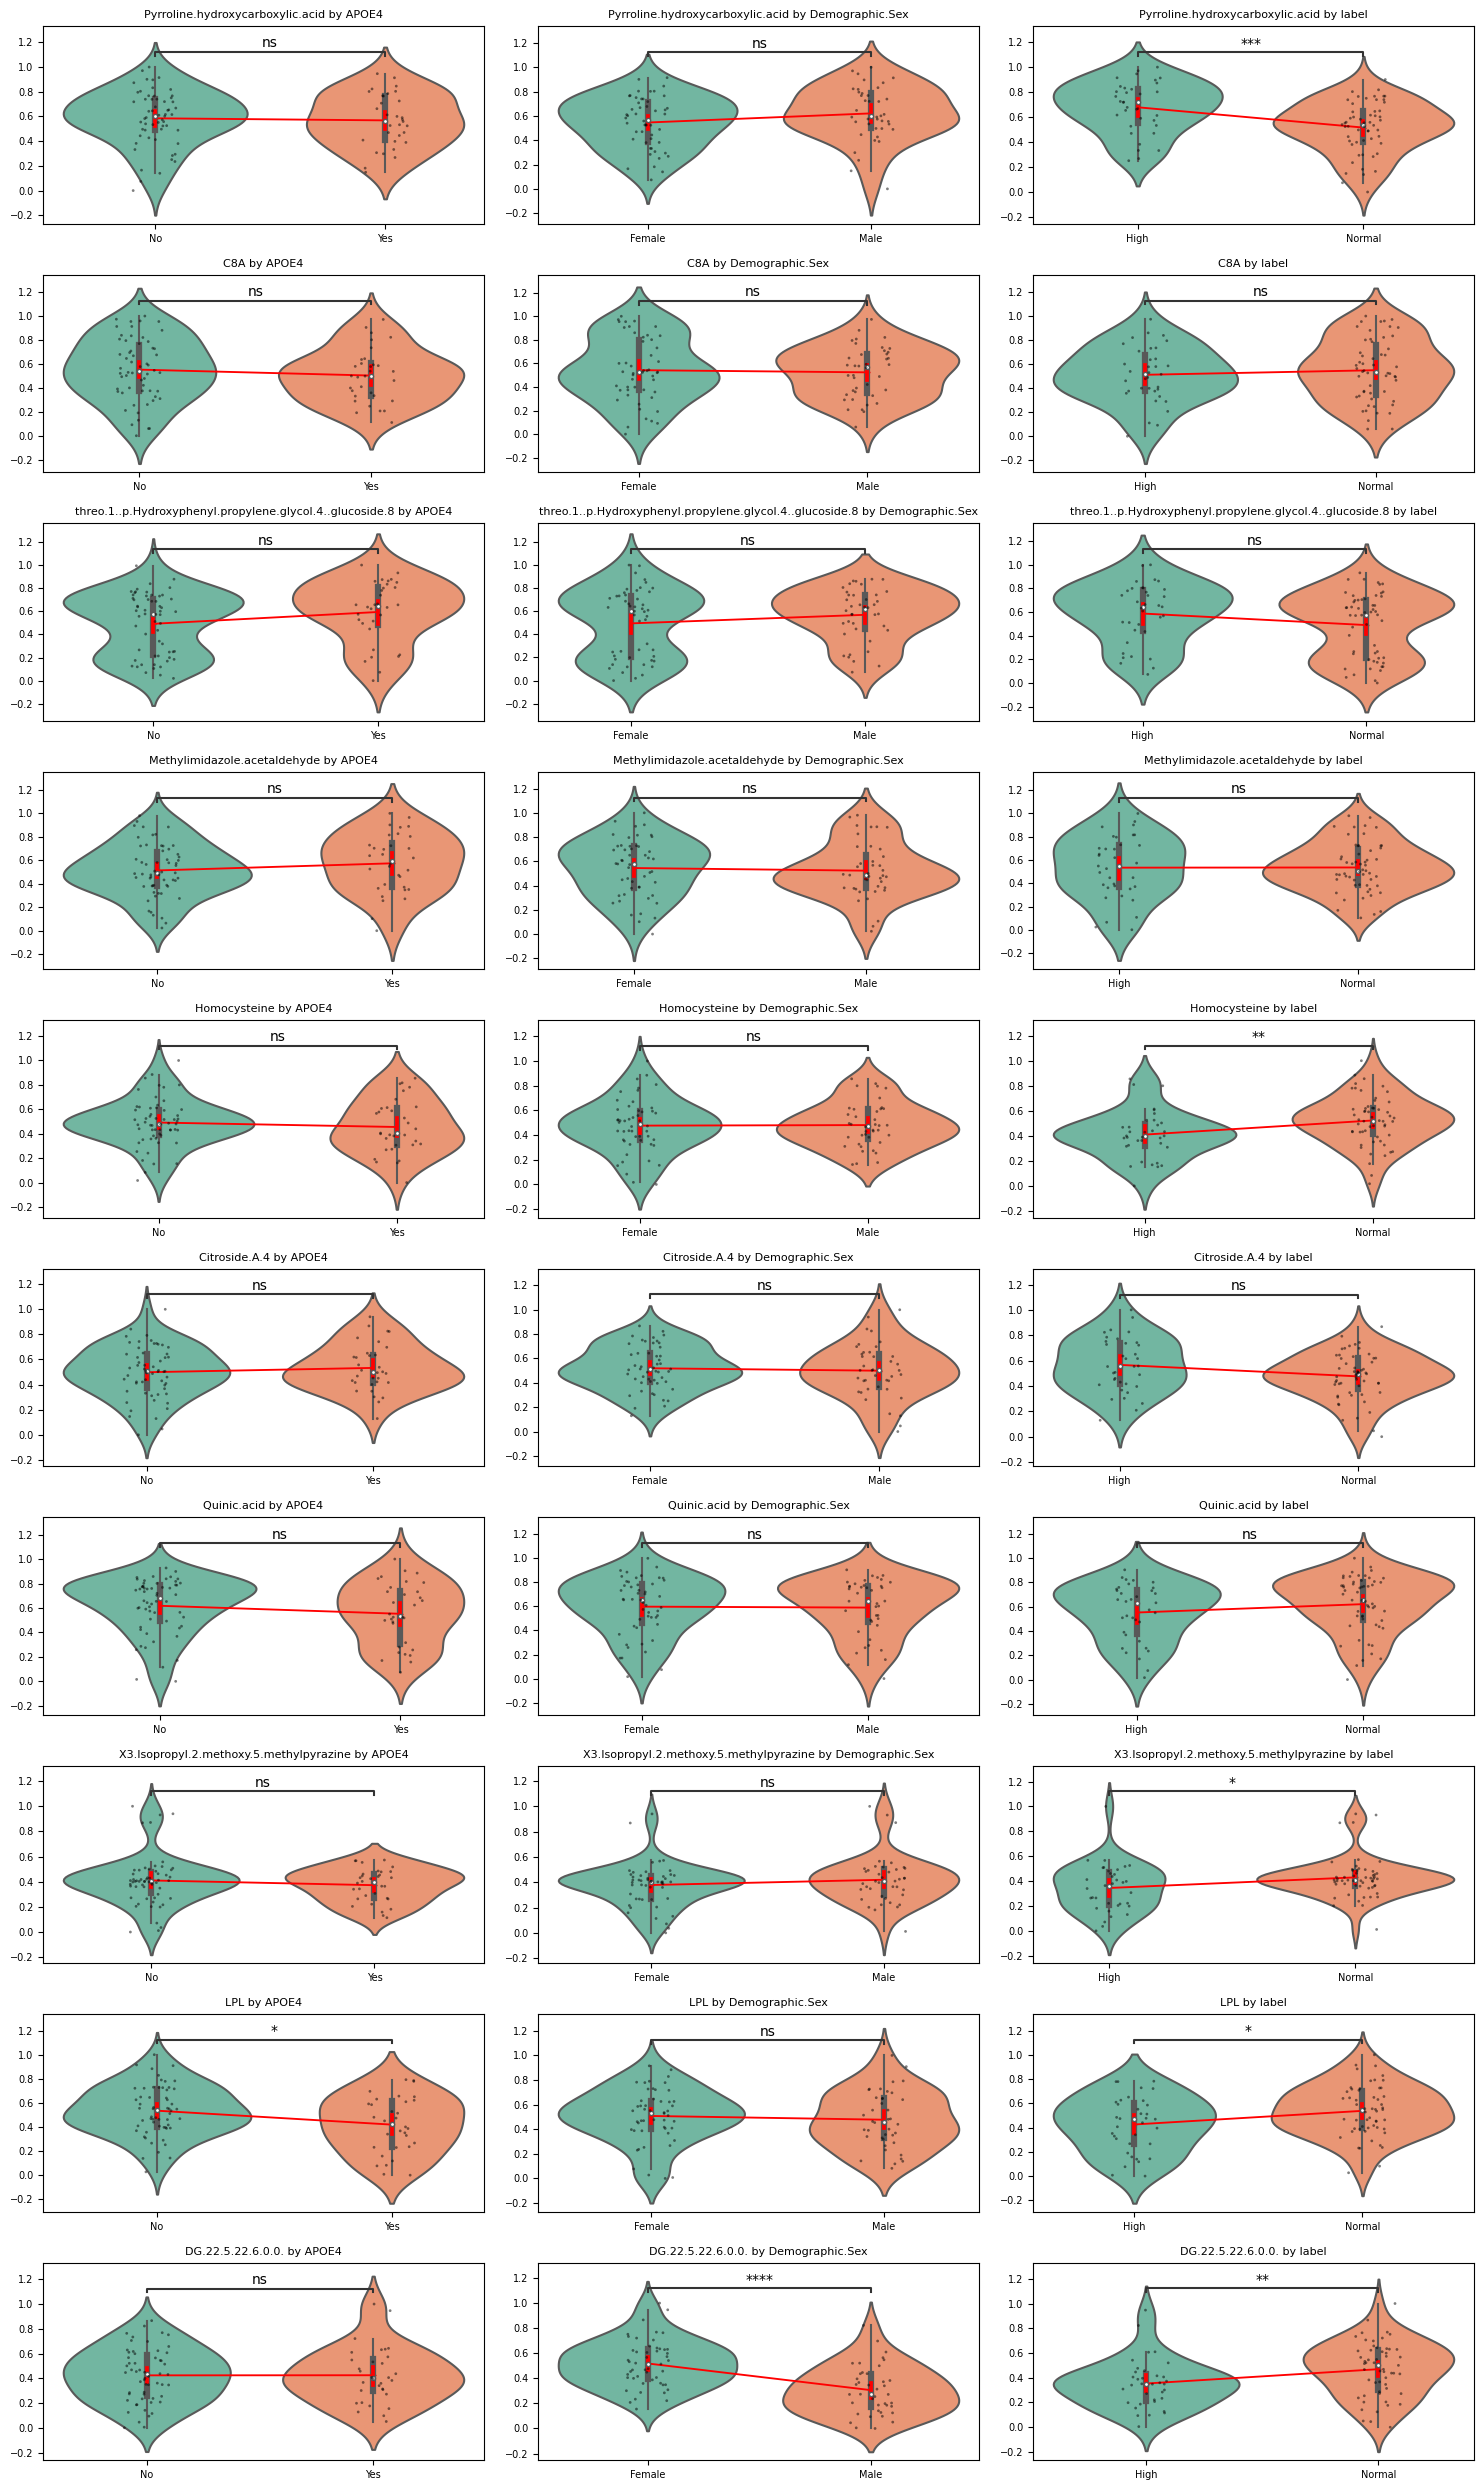

In [109]:
test_feature = ['Pyrroline.hydroxycarboxylic.acid', 'C8A', 'threo.1..p.Hydroxyphenyl.propylene.glycol.4..glucoside.8', 'Methylimidazole.acetaldehyde', 'Homocysteine', 
                'Citroside.A.4', 'Quinic.acid', 'X3.Isopropyl.2.methoxy.5.methylpyrazine', 'LPL',
                'DG.22.5.22.6.0.0.']
hue_list = ['APOE4','Demographic.Sex','label']

fig, axes = plt.subplots(nrows=len(test_feature), ncols=len(hue_list), figsize=(15, 25))
for i, feature in enumerate(test_feature):
    for j, hue in enumerate(hue_list):
        ax = axes[i, j]
        sns.violinplot(x=hue, y=feature, data=boxplot_df, ax=axes[i, j], palette="Set2")
        sns.stripplot(x=hue, y=feature, data=boxplot_df, ax=axes[i, j], color='k', size=2, alpha=0.5)
        sns.pointplot(x=hue, y=feature, data=boxplot_df, ax=axes[i, j], color='red', scale=0.5, ci=95, markers='_')

        unique_values = sorted(boxplot_df[hue].unique())
        pairs = [(str(unique_values[x]), str(unique_values[y])) for x in range(len(unique_values)) for y in range(x+1, len(unique_values))]
        annotator = Annotator(ax, pairs, data=boxplot_df, x=hue, y=feature)
        annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0)
        annotator.apply_and_annotate()

        axes[i, j].set_title(f'{feature} by {hue}', fontsize=8)
        axes[i, j].set_xlabel('', fontsize=8)
        axes[i, j].set_ylabel('', fontsize=8)

        axes[i, j].tick_params(axis='x', labelsize=7)  
        axes[i, j].tick_params(axis='y', labelsize=7) 

plt.tight_layout()
plt.show()

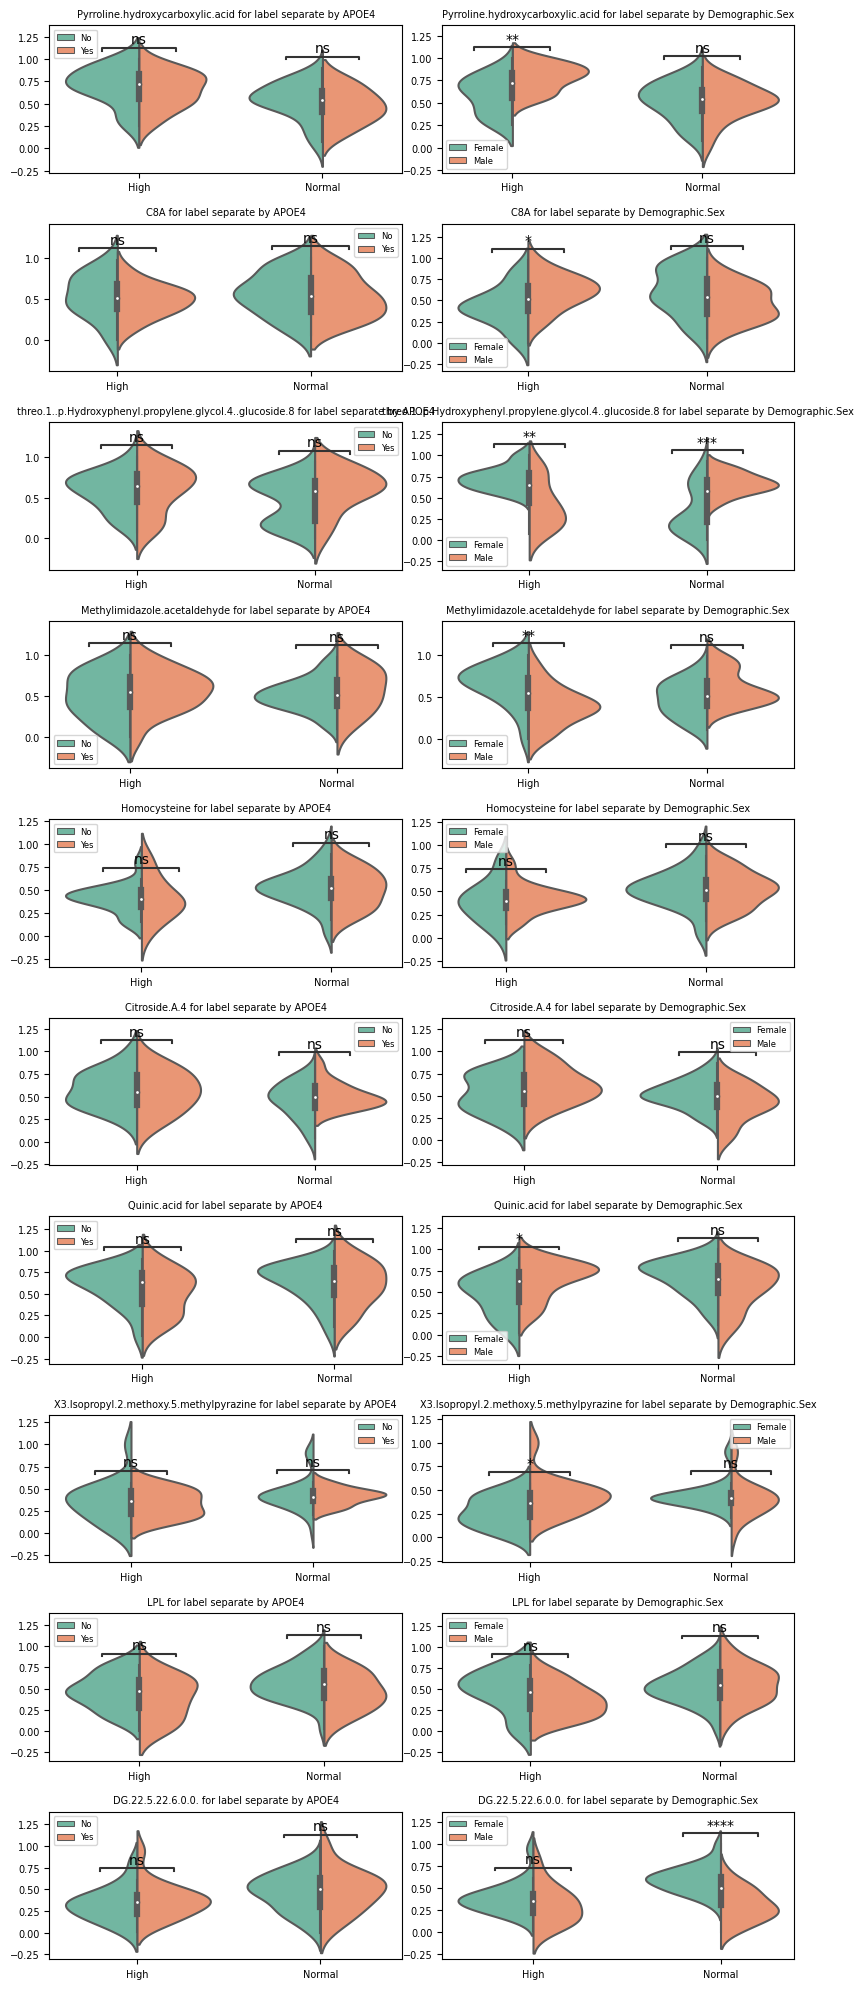

In [110]:
fig, axes = plt.subplots(nrows=len(test_feature), ncols=2, figsize=(8, 20))
for i, feature in enumerate(test_feature):
    for j, hue in enumerate(['APOE4','Demographic.Sex']):
        ax = axes[i, j]
        sns.violinplot(x='label', y=feature, data=boxplot_df, ax=axes[i, j],hue=hue, split=True, palette="Set2")

        labels = boxplot_df['label'].unique()
        hues = boxplot_df[hue].unique()
        pairs = [((label, hues[0]), (label, hues[1])) for label in labels]  # Pairing within each label

        annotator = Annotator(ax, pairs, data=boxplot_df, x='label', y=feature, hue=hue)
        annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0, line_offset=0.05) 
        annotator.apply_and_annotate()

        axes[i, j].set_title(f'{feature} for label separate by {hue}', fontsize=7)
        axes[i, j].set_xlabel('', fontsize=8)
        axes[i, j].set_ylabel('', fontsize=8)

        axes[i, j].tick_params(axis='x', labelsize=7)  
        axes[i, j].tick_params(axis='y', labelsize=7) 

        axes[i, j].legend(loc='best', fontsize=6)

plt.tight_layout()
plt.show()